In [1]:
from sklearn.datasets import load_breast_cancer
from src.gaussian_mixture import GaussianMixtureMAR
from sklearn.model_selection import train_test_split
import torch
import numpy as np

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

In [3]:
def ampute_mar(X, prop=0.2, seed=42):
    """
    X: complete tensor of shape (n_samples, n_features)
    prop: approximate proportion missing per feature
    Returns:
        X_missing: tensor with NaNs
        mask: True = observed, False = missing
    """
    X_missing = X.clone().float()
    n, p = X.shape

    if p < 2:
        raise ValueError("MAR requires at least two features.")
    if not 0 <= prop <= 1:
        raise ValueError("prop must be between 0 and 1.")

    generator = torch.Generator(device=X.device)
    generator.manual_seed(seed)

    # Standardize columns for comparable scales
    mean = X_missing.mean(dim=0)
    std = X_missing.std(dim=0).clamp_min(1e-8)
    Z = (X_missing - mean) / std

    missing = torch.zeros_like(X_missing, dtype=torch.bool)

    for j in range(p):
        # Other features determine missingness in feature j
        predictors = torch.cat([Z[:, :j], Z[:, j+1:]], dim=1)
        score = predictors.mean(dim=1)

        # Convert scores into probabilities
        prob = torch.sigmoid(score)

        # Select approximately prop * n values as missing
        n_missing = round(prop * n)
        if n_missing > 0:
            idx = torch.topk(prob, n_missing).indices
            missing[idx, j] = True

    X_missing[missing] = float("nan")
    return X_missing, ~missing

In [4]:
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
Xtrain = torch.tensor(Xtrain.to_numpy())
M = ampute_mar(Xtrain)[1]

In [5]:
model = GaussianMixtureMAR(k_range=(0,20))

In [6]:
M = M.int()

In [7]:
model.fit(Xtrain, M)

In [9]:
_, mu, _ = model.best_params

In [11]:
mu.shape

torch.Size([19, 30])

In [12]:
from sklearn.cluster import KMeans

# X: tensor of shape (19, 30)
mu_np = mu.detach().cpu().numpy()

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
labels = kmeans.fit_predict(mu_np)

labels = torch.tensor(labels)

print(labels)          # Cluster assignment for each observation
print(labels.shape)    # torch.Size([19])

tensor([1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1],
       dtype=torch.int32)
torch.Size([19])


In [13]:
kidx = model.which_cluster(Xtrain, M)

In [26]:
cluster1 = torch.where(labels==1)[0]
cluster1

tensor([ 0,  4,  6,  9, 18])

In [30]:
cluster = [1 if x in cluster1 else 0 for x in kidx]

In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

In [33]:
def pca_linearsep(X_train, y_train, X_test, y_test):
    # Perform PCA
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    pca = PCA(n_components=2)
    PC_pca = pca.fit_transform(X_train_scaled)
    
    # Fit linear SVC on the 2 principal components
    svc = LinearSVC(C=1.0, max_iter=10000)
    svc.fit(PC_pca, y_train)
    
    # Accuracy
    PC_test = pca.transform(scaler.transform(X_test))
    acc = accuracy_score(y_test, svc.predict(PC_test))

    w = svc.coef_[0]
    b = svc.intercept_[0]
    x_vals = np.linspace(PC_pca[:, 0].min(), PC_pca[:, 0].max(), 200)
    y_vals = -(w[0] * x_vals + b) / w[1]

    return PC_pca, -w[0]/w[1], -b/w[1], acc

In [34]:
PC_pca, slope, intercept, acc_full = pca_linearsep(Xtrain, ytrain, Xtest, ytest)

/Users/huimin/Documents/UNIGE PhD/research/nonparametric/.venv/lib/python3.11/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [39]:
import matplotlib.pyplot as plt

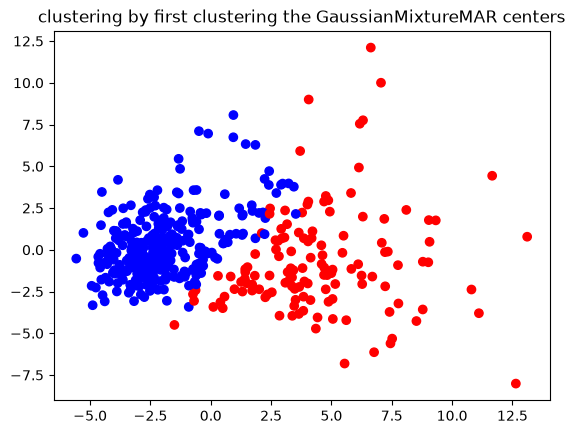

In [44]:
plt.scatter(PC_pca[:,0], PC_pca[:,1], c=np.where(cluster, 'red', 'blue'))
plt.title('clustering by first clustering the GaussianMixtureMAR centers')
plt.show()